# ASTR 457: The Midterm

Posted Thu Oct 8, due Wed Oct 14 by Noon (fork → PR, as always). Graded like a lab.

Three parts. Each is designed to test something every lab so far has come back to - which error bar is the right one, whether the model needs the extra parameter, and whether the check you ran could have failed. You've now got the tools to do all of this, so let's do it on numbers you haven't seen: 250 real Type Ia supernovae, and someone else's analysis of real white dwarfs.

Part 1 is 30 pts (6 each), Part 2 is 45 pts, and Part 3 is 25 pts. You'll need 2b and 2c right to get 2d right.

Remember, the rules are the syllabus rules - open book, you can use AI tools (document them in 3b), you can work together and discuss problems and solutions, but you have to write up your own solution and run it on **your own data** in `data/<your netid>/` (nobody else's numbers will match yours).

Put your notebook in `submissions/<your netid>/midterm.ipynb`. The path below (`DATA`) reaches your files from there. Make sure it runs top to bottom from a fresh kernel ("Restart & Run All") - that is how it will be graded, and how it will be run if you defend it.

Throughout, make sure every number you quote has a unit, an error bar and a sensible number of digits (two significant figures on the error bar, and round the value to match).

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

NETID = 'elinas2'   # <-- set this
DATA = f'../../labs/midterm/data/{NETID}/'   # from submissions/<your netid>/

def load(name):
    """Read one of your CSV files as a pandas table; d['column'].to_numpy() gives a numpy array. Names stay strings."""
    return pd.read_csv(DATA + name + '.csv', dtype={'name': str})

## Part 1: Error bars (30 pts, 6 each)

Five short scenarios. Each one is a number someone handed you - say whether it's right, compute the right one, and say in a sentence or two why. Show the code. Each of these should be about 20 minutes of work.

### 1a - The extinction coefficient (`p1a_extinction.csv`)

An observer measured a photometric zero point at 15 different airmasses through one night. Extinction in magnitudes grows in proportion to the airmass $X$, so the zero point should follow a line, $m = k\,X + m_0$, where $k$ is the extinction coefficient in mag per airmass. Columns: `airmass`, `zeropoint_mag`, `sigma_quoted_mag` (the pipeline's error on each point).

1. Fit the line by weighted least squares with the quoted errors. Report $k$ and its error bar computed from the quoted errors alone.
2. Now run `np.polyfit(airmass, zeropoint_mag, 1, w=1/sigma_quoted_mag, cov=True)` and report its error bar on $k$. Explain exactly what `polyfit` did to get a different number (read its documentation for `cov`).
3. Compute $\chi^2$ and the number of degrees of freedom. How probable is a $\chi^2$ this large or this small if the quoted errors were right? (Compute it from the $\chi^2$ distribution.)
4. Report the error bar on $k$ you'd quote, and justify it. What does your answer to (3) tell you about the pipeline's error bars?

In [32]:
# 1a: your work here

import numpy as np
from scipy.stats import chi2

data= load('p1a_extinction')
x = data["airmass"]
y = data["zeropoint_mag"]
sigma = data["sigma_quoted_mag"]

# (1) Weighted least squares using quoted errors
A = np.column_stack((x, np.ones_like(x)))
W = np.diag(1 / sigma**2)

cov_quoted = np.linalg.inv(A.T @ W @ A)
params = cov_quoted @ A.T @ W @ y

m, b = params
k = -m
k_err_quoted = np.sqrt(cov_quoted[0, 0])

print("Extinction coefficient k =", k)
print("Quoted-error uncertainty =", k_err_quoted)

# (2) np.polyfit with covariance scaling
p, cov_poly = np.polyfit(x, y, 1, w=1/sigma, cov=True)

k_err_poly = np.sqrt(cov_poly[0, 0])
print("polyfit uncertainty =", k_err_poly)

# (3) Chi-square and probabilities
y_fit = A @ params
chi2_val = np.sum(((y - y_fit) / sigma)**2)

dof = len(x) - 2
chi2_red = chi2_val / dof

p_large = chi2.sf(chi2_val, dof)
p_small = chi2.cdf(chi2_val, dof)

print("Chi-square =", chi2_val)
print("Degrees of freedom =", dof)
print("Reduced chi-square =", chi2_red)
print("P(chi-square >= observed) =", p_large)
print("P(chi-square <= observed) =", p_small)

# (4) Compare uncertainties
print("Error scaling factor =", np.sqrt(chi2_red))

if chi2_red > 1:
    print("Excess scatter; investigate underestimated errors or systematics.")
elif chi2_red < 1:
    print("Less scatter than expected; investigate overestimated errors or correlations.")
else:
    print("Scatter consistent with quoted errors.")


Extinction coefficient k = -0.22520436693793755
Quoted-error uncertainty = 0.01289512543004968
polyfit uncertainty = 0.025673258030753307
Chi-square = 51.529292792119
Degrees of freedom = 13
Reduced chi-square = 3.9637917532399234
P(chi-square >= observed) = 1.6258378869224659e-06
P(chi-square <= observed) = 0.9999983741621131
Error scaling factor = 1.9909273601113435
Excess scatter; investigate underestimated errors or systematics.


**ANSWER:**
k = -0.22520436693793755
Quoted-error uncertainty = 0.01289512543004968polyfit uncertainty = 0.025673258030753307
polyfit cales the covariance matrix by the reduced chi^2, unless cov='unscaled' is used. The fit gives chi sqaure 51.529292792119 for 13 degrees of freedom. If the quoted errors were correct, getting a chi-square this large would be extremely unlikely. The formal error on k is 0.0129, but because the reduced chi-square is 3.96, I scale the error by sqrt{3.96}=1.99. So I would report k=-0.2252 +- 0.0257 mag/airmass..

### 1b - The centroid (`p1b_centroid.csv`)

A classmate measured the position of a star from `n_photons` photons, each landing at a position drawn from a Gaussian of width `psf_sigma_arcsec` around the true position. They report an error on the position of `quoted_sigma_x0_arcsec`, from a clever weighting scheme they found online.

1. Compute the Cramér-Rao bound on the error of any unbiased estimator of the position (Lab 02).
2. Is the quoted error possible? If not, say what the classmate's number must mean instead, and name two concrete mistakes that would produce an error bar this small.

In [33]:
# 1b: your work here
p1b=load('p1b_centroid')

cr_bound = p1b['psf_sigma_arcsec'].iloc[0] / np.sqrt(p1b['n_photons'].iloc[0])

print("Cramer-Rao bound =", cr_bound, "arcsec")
print("Quoted error =", p1b['quoted_sigma_x0_arcsec'].iloc[0], "arcsec")

Cramer-Rao bound = 0.0801907931769279 arcsec
Quoted error = 0.0491312 arcsec


**ANSWER:**


The Cramér–Rao bound is \(0.0802\) arcsec, whereas the quoted error is \(0.0491\) arcsec. Because the quoted value is smaller than the CR bound, it cannot represent the true 1 sig sampling uncertainty of an unbiased position estimator under this model. It must instead be an underestimated formal/internal error.

### 1c - The transit depth's error bar (`p1c_profile.csv`)

A transit-depth fit produced this profile: columns `depth_ppt` (the depth, in parts per thousand) and `minus2lnL` ($-2\ln L$ at that depth, other parameters fixed at their best values). A classmate took the second derivative of `minus2lnL` at its minimum and reported $\sigma = 1/\sqrt{d^2(-2\ln L)/d\,\textrm{depth}^2}$.

1. Find the best depth and the correct $1\sigma$ error from the curvature. Is the classmate's error bar right? If not, by what factor is it off, and why?
2. Read the $\Delta(-2\ln L) = 1$ interval directly off the profile. Is it symmetric? Compare it with your curvature answer.
3. If the classmate quotes $\pm$ their $\sigma$ on many independent datasets, what fraction of those intervals contain the true depth? Predict it, then check it with a simulation (a few thousand fake best-fit depths drawn around a truth you choose, using your correct $\sigma$).

In [4]:
# 1c: your work here
p1c=load('p1c_profile')

depth=p1c['depth_ppt'].to_numpy()
m2lnL=p1c['minus2lnL'].to_numpy()

imin=np.argmin(m2lnL)
depth_best=depth[imin]
m2min=m2lnL[imin]

print("Best depth =",depth_best,"ppt")
nfit=5
lo=max(0,imin-nfit)
hi=min(len(depth),imin+nfit+1)

coef=np.polyfit(depth[lo:hi],m2lnL[lo:hi],2)

a,b,c=coef
depth_curv=-b/(2*a)

second_deriv=2*a
sigma_correct=np.sqrt(2/second_deriv)
sigma_classmate=1/np.sqrt(second_deriv)

print("Best depth from curvature =",depth_curv,"ppt")
print("Correct 1-sigma =",sigma_correct,"ppt")
print("Classmate error =",sigma_classmate,"ppt")
print("Factor correct/classmate =",sigma_correct/sigma_classmate)

Best depth = 3.83877 ppt
Best depth from curvature = 3.838359061481927 ppt
Correct 1-sigma = 0.22662485944107263 ppt
Classmate error = 0.16024797489623066 ppt
Factor correct/classmate = 1.414213562373095


In [5]:
target=m2min+1

left_depth=depth[:imin+1]
left_y=m2lnL[:imin+1]

right_depth=depth[imin:]
right_y=m2lnL[imin:]

left_cross=np.interp(target,left_y[::-1],left_depth[::-1])
right_cross=np.interp(target,right_y,right_depth)

err_minus=depth_best-left_cross
err_plus=right_cross-depth_best

print("Delta(-2lnL)=1 interval:")
print(left_cross,right_cross)
print("depth =",depth_best,f"-{err_minus:.4f} +{err_plus:.4f} ppt")

Delta(-2lnL)=1 interval:
3.609865194294147 4.063035102249489
depth = 3.83877 -0.2289 +0.2243 ppt


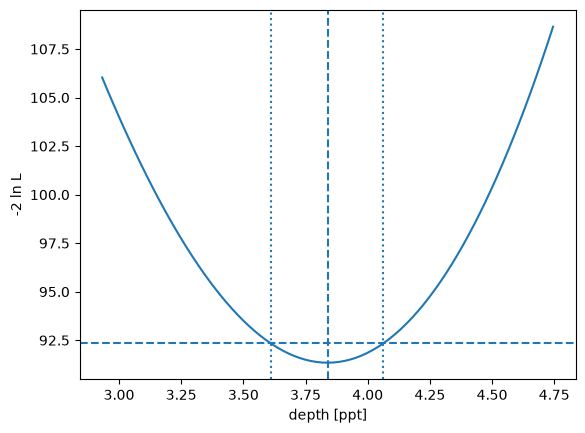

Left error = 0.2289048057058527
Right error = 0.22426510224948926
Curvature error = 0.22662485944107263


In [6]:
plt.plot(depth,m2lnL)
plt.axhline(m2min+1,ls='--')
plt.axvline(depth_best,ls='--')
plt.axvline(left_cross,ls=':')
plt.axvline(right_cross,ls=':')
plt.xlabel('depth [ppt]')
plt.ylabel('-2 ln L')
plt.show()
print("Left error =",err_minus)
print("Right error =",err_plus)
print("Curvature error =",sigma_correct)

In [7]:
from scipy.stats import norm

coverage_pred=2*norm.cdf(1/np.sqrt(2))-1
print("Predicted coverage =",coverage_pred)
rng=np.random.default_rng(42)

truth=10.0
nsim=5000

fake_best=rng.normal(truth,sigma_correct,nsim)

wrong_sigma=sigma_correct/np.sqrt(2)

inside=(truth>=fake_best-wrong_sigma)&(truth<=fake_best+wrong_sigma)

print("Predicted coverage =",coverage_pred)
print("Simulated coverage =",inside.mean())

Predicted coverage = 0.5204998778130465
Predicted coverage = 0.5204998778130465
Simulated coverage = 0.5276


**ANSWER:**
The best-fit transit depth is about 3.839 ppt. From the curvature, the correct 1 sigma error is 0.227 ppt. The classmate’s value, 0.160 ppt, is too small by a factor of \(\sqrt{2}\approx1.41\), because the profile is \(-2\ln L\), not \(-\ln L\).

The direct \(\Delta(-2\ln L)=1\) interval is \(3.610\) to \(4.063\) ppt, or \(3.839^{+0.224}_{-0.229}\) ppt. It is only slightly asymmetric and agrees well with the curvature error.

The classmate’s too-small intervals should contain the true value only about \(52.0\%\) of the time instead of \(68\%\). The simulation gave \(52.76\%\), which agrees with the prediction.

### 1d - The companion mass (`p1d_mass_samples.csv`)

These are 8000 posterior samples of the mass of an unseen companion, `M2_Msun`. Three classmates report its uncertainty as (i) the variance of the samples, (ii) the 84th percentile minus the 16th, and (iii) the standard deviation divided by $\sqrt{8000}$.

1. Report the mass as a median with its 16th-84th percentile error bars, in solar masses.
2. For each of (i)-(iii): what quantity is it actually, what are its units, and by roughly what factor is it wrong as a $1\sigma$ error bar?
3. Is a symmetric $\pm$ error bar appropriate for this posterior? If not, show why.

In [8]:
# 1d: your work here
p1d=load('p1d_mass_samples')

m=p1d['M2_Msun'].to_numpy()
N=len(m)

q16,q50,q84=np.percentile(m,[16,50,84])

err_lo=q50-q16
err_hi=q84-q50

variance=np.var(m,ddof=1)
sd=np.std(m,ddof=1)
width_16_84=q84-q16
sem=sd/np.sqrt(N)

print(f"M2 = {q50:.4f} -{err_lo:.4f} +{err_hi:.4f} Msun")
print("variance =",variance,"Msun^2")
print("84th-16th =",width_16_84,"Msun")
print("standard deviation =",sd,"Msun")
print("sd/sqrt(N) =",sem,"Msun")

print("variance / typical 1sigma =",variance/((err_lo+err_hi)/2))
print("(84-16) / typical 1sigma =",width_16_84/((err_lo+err_hi)/2))
print("SEM / typical 1sigma =",sem/((err_lo+err_hi)/2))

M2 = 6.4454 -1.4739 +1.8983 Msun
variance = 3.065383142472084 Msun^2
84th-16th = 3.3721616 Msun
standard deviation = 1.7508235612054357 Msun
sd/sqrt(N) = 0.01957480249731809 Msun
variance / typical 1sigma = 1.8180523391714585
(84-16) / typical 1sigma = 2.0
SEM / typical 1sigma = 0.011609646760296475


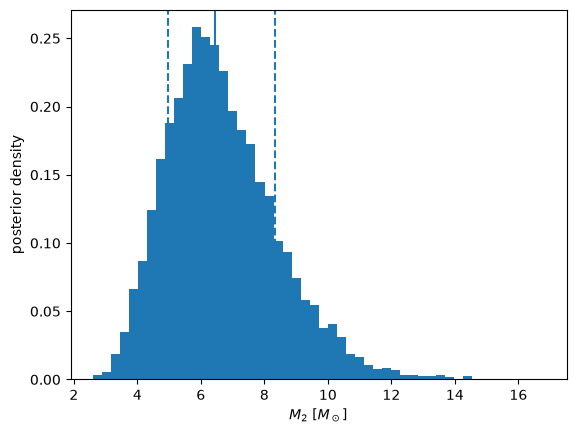

lower error = 1.4738690000000005
upper error = 1.8982925999999996
asymmetry ratio = 1.2879656197396097


In [9]:
plt.hist(m,bins=50,density=True)
plt.axvline(q16,ls='--')
plt.axvline(q50)
plt.axvline(q84,ls='--')
plt.xlabel(r'$M_2\ [M_\odot]$')
plt.ylabel('posterior density')
plt.show()

print("lower error =",err_lo)
print("upper error =",err_hi)
print("asymmetry ratio =",err_hi/err_lo)

**ANSWER:**

*your answer goes here*

### 1e - The slope at fixed intercept (`p1e_slope_intercept_samples.csv`)

Posterior samples of a slope and an intercept from a line fit. A classmate fixed the intercept at its best value, refit only the slope, and quoted the slope's error from that 1-D fit.

1. Compute the slope's error bar the classmate got (the spread of the slope *at fixed intercept*), and the marginal one (the spread of the slope with the intercept marginalized over).
2. Compute their ratio, and the correlation coefficient $\rho$ of the samples. How does the ratio depend on $\rho$? Plot the samples and draw both error bars on the plot.
3. When is the classmate's number the right one to quote? One sentence.

In [10]:
# 1e: your work here
p1e=load('p1e_slope_intercept_samples')

slope=p1e['slope'].to_numpy()
intercept=p1e['intercept'].to_numpy()

rho=np.corrcoef(slope,intercept)[0,1]

sigma_slope=np.std(slope,ddof=1)
sigma_intercept=np.std(intercept,ddof=1)

sigma_fixed=sigma_slope*np.sqrt(1-rho**2)
sigma_marg=sigma_slope

print("rho =",rho)
print("fixed-intercept sigma_slope =",sigma_fixed)
print("marginal sigma_slope =",sigma_marg)
print("fixed/marginal =",sigma_fixed/sigma_marg)
print("sqrt(1-rho^2) =",np.sqrt(1-rho**2))

rho = -0.9065703446902792
fixed-intercept sigma_slope = 0.024303538375536678
marginal sigma_slope = 0.057583852576153303
fixed/marginal = 0.42205474778534163
sqrt(1-rho^2) = 0.42205474778534163


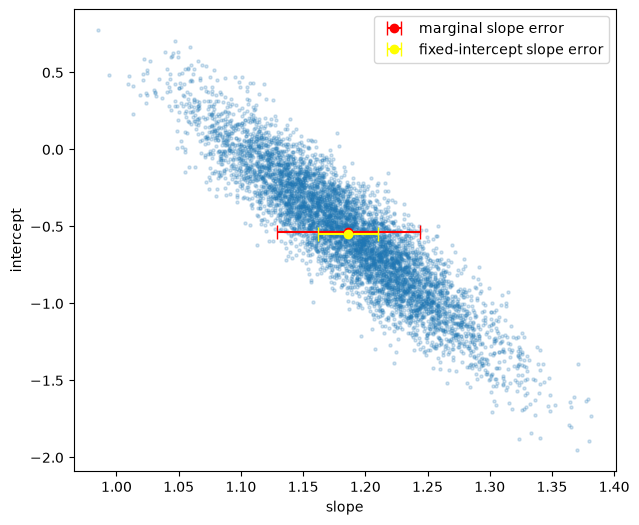

In [36]:
s0=np.median(slope)
b0=np.median(intercept)

plt.figure(figsize=(7,6))
plt.scatter(slope,intercept,s=5,alpha=.2)

plt.errorbar(s0,b0,xerr=sigma_marg,fmt='o',capsize=5,label='marginal slope error', color='red')
plt.errorbar(s0,b0-0.03*sigma_intercept,xerr=sigma_fixed,
             fmt='o',capsize=5,label='fixed-intercept slope error',color='yellow')

plt.xlabel('slope')
plt.ylabel('intercept')
plt.legend()
plt.show()

**ANSWER:**
he slope uncertainty with the intercept fixed is 0.0243, while the marginal slope uncertainty is 0.0576. The fixed-intercept error is only about 42% of the marginal error. The slope and intercept are strongly negatively correlated, with rho=-0.907. The fixed-intercept error is appropriate only if the intercept is truly known exactly; otherwise the marginal error should be quoted.

## Part 2: 250 supernovae and a step (45 pts)

Type Ia supernovae are standardizable candles: their peak brightness, corrected for how fast they fade and for their color, measures distance well enough to have discovered cosmic acceleration. Your file `p2_pantheon_sne.csv` holds 250 real SNe Ia from the Pantheon+ compilation (Scolnic et al. 2022, ApJ 938, 113; [Brout et al. 2022](https://arxiv.org/abs/2202.04077), ApJ 938, 110), all at redshift $0.023 < z < 0.15$. For each supernova, a light-curve fit (SALT2) gives:

- `mB`: the peak apparent magnitude in the B band, and `mB_err`;
- `x1`: the light-curve *stretch* (broader light curves are brighter), and `x1_err`;
- `c`: the *color* (redder supernovae are fainter, from dust and intrinsically), and `c_err`;
- `cov_mB_x1`, `cov_mB_c`, `cov_x1_c`: the covariances between those three, from the same light-curve fit;
- `z`: the redshift; `host_logmass`, `host_logmass_err`: $\log_{10}$ of the host galaxy's stellar mass in solar masses, and its error.

The standardized brightness is the **Tripp relation**,

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10),$$

where $M$ is the absolute magnitude of a "standard" SN Ia, $\mu(z)$ the distance modulus, $\Theta$ is 1 for hosts more massive than $10^{10}\,M_\odot$ and 0 otherwise, and $\gamma$ is the **host-mass step**. Supernovae in massive hosts appear to be brighter after standardization (Kelly et al. 2010; Sullivan et al. 2010); whether the step is real, and why, matters for supernova dark-energy measurements. In this form, a step that makes supernovae in massive hosts brighter has $\gamma < 0$; the published value is about $\gamma \approx -0.06$ mag. So the question for your sample is whether you need $\gamma$ at all.

There are two more things you'll need. At these redshifts the galaxies' own motions (peculiar velocities, about 250 km/s) shift $z$, and so $\mu$; add $\sigma_{\mu,\rm pec} = \frac{5}{\ln 10}\frac{250\ {\rm km/s}}{c\,z}$ to each supernova's variance. And no supernova is a perfect standard candle: add an intrinsic scatter $\sigma_{\rm int}$, a free parameter. Use a flat $\Lambda$CDM distance modulus with $H_0 = 70$ km/s/Mpc and $\Omega_m = 0.3$ (`astropy.cosmology.FlatLambdaCDM(H0=70, Om0=0.3).distmod(z)`); $M$ absorbs the choice of $H_0$.

We planted between **two and four contaminants** in your file - objects whose `mB` we made fainter by more than a magnitude, so they are not standard SNe Ia any more (think of a mis-classified peculiar supernova). Their names are not in the file. Real data have a few real outliers too, so not everything far from the line is planted.

### 2a - Look at the data (5 pts)

1. Compute $\mu(z)$ and plot the **Hubble residuals** $m_B - \mu(z)$ against $x_1$, against $c$, and against `host_logmass`.
2. Which way do the $x_1$ and $c$ trends go? Is that the sign the Tripp relation expects? Two or three sentences.
3. The raw trend with host mass may not have the sign of $\gamma$. Why not? (Plot $x_1$ against host mass.)
4. Can you see any of the contaminants?
5. What units do $\alpha$ and $\beta$ have?

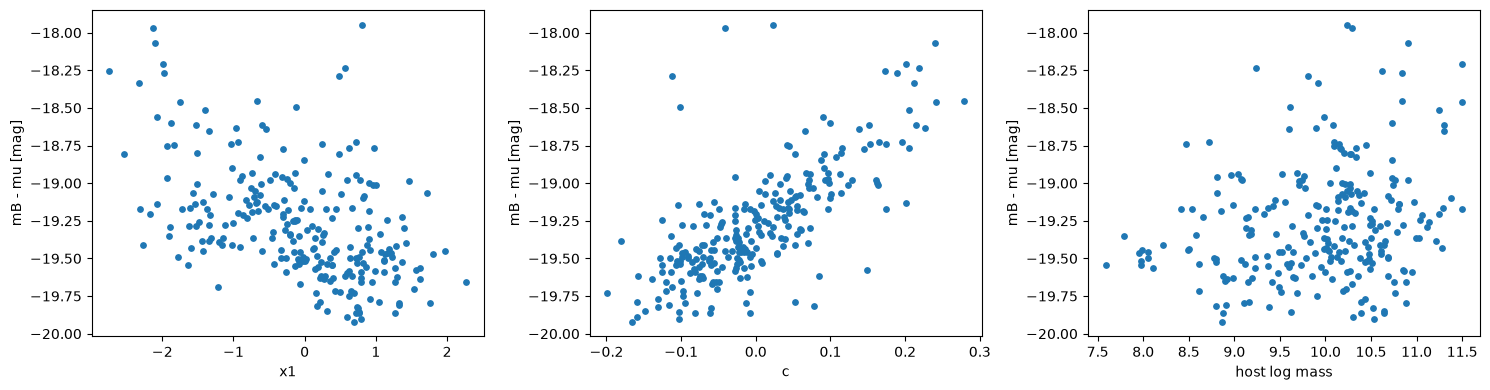

In [12]:
# 2a: your work here
from astropy.cosmology import FlatLambdaCDM

p2=load('p2_pantheon_sne')

cosmo=FlatLambdaCDM(H0=70,Om0=0.3)

z=p2['z'].to_numpy()
mB=p2['mB'].to_numpy()
x1=p2['x1'].to_numpy()
c=p2['c'].to_numpy()
host=p2['host_logmass'].to_numpy()

mu=cosmo.distmod(z).value
hres=mB-mu

fig,ax=plt.subplots(1,3,figsize=(15,4))

ax[0].scatter(x1,hres,s=15)
ax[0].set_xlabel('x1')
ax[0].set_ylabel('mB - mu [mag]')

ax[1].scatter(c,hres,s=15)
ax[1].set_xlabel('c')
ax[1].set_ylabel('mB - mu [mag]')

ax[2].scatter(host,hres,s=15)
ax[2].set_xlabel('host log mass')
ax[2].set_ylabel('mB - mu [mag]')

plt.tight_layout()
plt.show()

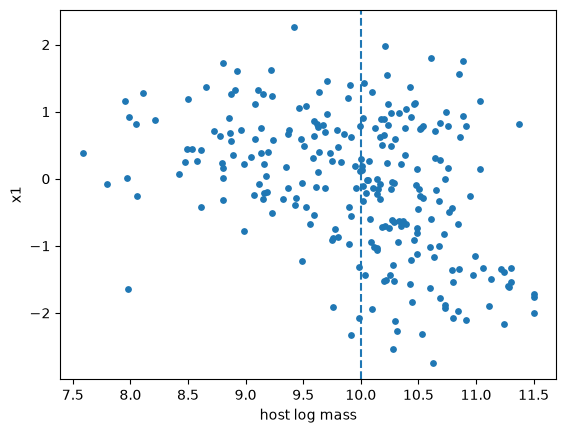

possible contaminants: [  0  32  62 199 206]
number: 5
residuals: [ 1.33754511  1.4049241   1.14448653  1.01998731 -0.74347153]


In [13]:
plt.scatter(host,x1,s=15)
plt.axvline(10,ls='--')
plt.xlabel('host log mass')
plt.ylabel('x1')
plt.show()
X=np.column_stack((np.ones(len(p2)),x1,c,(host>10).astype(float)))
coef=np.linalg.lstsq(X,hres,rcond=None)[0]
prelim=X@coef
r=hres-prelim

med=np.median(r)
mad=1.4826*np.median(np.abs(r-med))

bad=np.abs(r-med)>5*mad

print("possible contaminants:",np.where(bad)[0])
print("number:",bad.sum())
print("residuals:",r[bad])

**ANSWER:**

*your answer goes here*

### 2b - The likelihood (10 pts)

The parameters are $\theta = (M, \alpha, \beta, \gamma, \sigma_{\rm int})$. Each supernova's variance is

$$\sigma_i^2 = \mathbf{v}^T C_i\,\mathbf{v} + \sigma_{\mu,{\rm pec},i}^2 + \sigma_{\rm int}^2, \qquad \mathbf{v} = (1, \alpha, -\beta),$$

where $C_i$ is that supernova's $3\times3$ covariance of $(m_B, x_1, c)$.

1. Write out $\mathbf{v}^T C_i\,\mathbf{v}$ term by term, and explain in one sentence why the off-diagonal terms are there.
2. Write the log-likelihood. Remember the $\ln\sigma_i^2$ term - the variance depends on the parameters.
3. State a prior for every parameter, and justify each in one line.
4. Decide whether to sample $\ln\sigma_{\rm int}$ or $\sigma_{\rm int}$, and say why.
5. Decide what to do about the contaminants. You may model them or remove them, but say how you found them and what a cut would cost you.

In [14]:
# 2b: your work here
good=~bad

d=p2.loc[good].reset_index(drop=True)

z=d['z'].to_numpy()
mB=d['mB'].to_numpy()
x1=d['x1'].to_numpy()
c=d['c'].to_numpy()
host=d['host_logmass'].to_numpy()

mu=cosmo.distmod(z).value

mb_err=d['mB_err'].to_numpy()
x1_err=d['x1_err'].to_numpy()
c_err=d['c_err'].to_numpy()

cov_mx=d['cov_mB_x1'].to_numpy()
cov_mc=d['cov_mB_c'].to_numpy()
cov_xc=d['cov_x1_c'].to_numpy()

step=(host>10).astype(float)

c_kms=299792.458
sigma_pec=(5/np.log(10))*250/(c_kms*z)

In [15]:
def log_prior(theta):
    M,alpha,beta,gamma,lns=theta

    if not -20.5<M<-18.0: return -np.inf
    if not 0<alpha<0.5: return -np.inf
    if not 0<beta<6: return -np.inf
    if not -0.5<gamma<0.5: return -np.inf
    if not np.log(0.001)<lns<np.log(1.0): return -np.inf

    return 0.0

def log_likelihood(theta):
    M,alpha,beta,gamma,lns=theta
    sint=np.exp(lns)

    model=M+mu-alpha*x1+beta*c+gamma*step

    var=(mb_err**2
         +alpha**2*x1_err**2
         +beta**2*c_err**2
         +2*alpha*cov_mx
         -2*beta*cov_mc
         -2*alpha*beta*cov_xc
         +sigma_pec**2
         +sint**2)

    if np.any(var<=0):
        return -np.inf

    return -0.5*np.sum((mB-model)**2/var+np.log(2*np.pi*var))

def log_posterior(theta):
    lp=log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp+log_likelihood(theta)

**ANSWER:**

*your answer goes here*

### 2c - Sampling and convergence (12 pts)

1. Find the maximum a posteriori point. Then run **four independent chains** from starting points spread wider than the posterior (you choose how, and say how you chose). Any sampler is fine - your own Metropolis, `emcee` (one ensemble per chain), or `PyMC`.
2. Report $\hat R$ and the effective sample size for every parameter (`arviz.rhat`, `arviz.ess`, or `arviz.summary`), and say what values would have made you run longer.
3. Make a corner plot, and quote $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 16th-84th percentile error bars.
4. Which parameters are correlated strongly? Comment on why. Then fix $M$ at its MAP value, refit $\gamma$, and compare that $\sigma_\gamma$ with the marginal one (cf. 1e).

`ArviZ` 1.x (install it with `conda install -c conda-forge pymc arviz`, as in `INSTALL.txt`) takes your chains as a dictionary of arrays shaped (chain, draw): `idata = az.from_dict({'posterior': {'alpha': a, 'beta': b}})`, then `az.summary(idata)`.

In [17]:
# 2c: your work here
import emcee
import corner
import arviz as az
theta0=np.array([-19.3,0.14,3.0,-0.05,np.log(0.1)])

res=minimize(lambda x:-log_posterior(x),theta0,method='Nelder-Mead')

map_par=res.x

print("MAP:")
print("M alpha beta gamma ln(sigma_int)")
print(map_par)
print("sigma_int =",np.exp(map_par[4]))

centers=[
    map_par+np.array([ 0.10, 0.03, 0.4, 0.08, 0.20]),
    map_par+np.array([-0.10,-0.03,-0.4,-0.08,-0.20]),
    map_par+np.array([ 0.05,-0.04, 0.5,-0.10, 0.15]),
    map_par+np.array([-0.05, 0.04,-0.5, 0.10,-0.15])
]

nwalkers=40
ndim=5
nsteps=10000

samplers=[]

for j,center in enumerate(centers):
    rng=np.random.default_rng(100+j)

    scale=np.array([0.01,0.01,0.05,0.01,0.03])
    start=center+scale*rng.normal(size=(nwalkers,ndim))

    sampler=emcee.EnsembleSampler(nwalkers,ndim,log_posterior)
    sampler.run_mcmc(start,nsteps,progress=True)

    samplers.append(sampler)

for j,s in enumerate(samplers):
    try:
        tau=s.get_autocorr_time()
        print(j,"tau =",tau,"N/tau min =",nsteps/tau.max())
    except emcee.autocorr.AutocorrError as e:
        print("chain",j,"not long enough")
        print(e)

taus=np.array([s.get_autocorr_time() for s in samplers])
tau_max=taus.max()

burn=int(3*tau_max)
thin=max(1,int(tau_max/2))

chains=[]

for s in samplers:
    ch=s.get_chain(discard=burn,thin=thin,flat=False)
    chains.append(ch.reshape(-1,ndim))

minlen=min(len(x) for x in chains)
chains=np.array([x[:minlen] for x in chains])

print(chains.shape)

MAP:
M alpha beta gamma ln(sigma_int)
[-19.27156394   0.13798604   2.96703784  -0.049184    -2.19098365]
sigma_int = 0.11180671592126179


100%|██████████| 10000/10000 [00:55<00:00, 180.56it/s]


0 tau = [53.12188534 55.76817449 51.9804492  54.63479116 57.82423225] N/tau min = 172.93787761573924
1 tau = [54.26166215 54.5800777  56.24946914 52.4297658  52.05138609] N/tau min = 177.77945556152028
2 tau = [57.94872239 52.59971614 55.16118261 55.75741049 52.81019723] N/tau min = 172.56635845000665
3 tau = [54.58911504 55.29118281 55.32138316 54.25499557 54.78889529] N/tau min = 180.76193017318494
(4, 14000, 5)


In [21]:
idata=az.from_dict({
    "posterior":{
        "M":chains[:,:,0],
        "alpha":chains[:,:,1],
        "beta":chains[:,:,2],
        "gamma":chains[:,:,3],
        "sigma_int":np.exp(chains[:,:,4])
    }
})

summary=az.summary(idata)
display(summary)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
M,-19.2716,0.01411,-19,-19,55275,54601,1.00,6e-05,4.3e-05
alpha,0.1381,0.00972,0.12,0.15,55019,55054,1.00,4.1e-05,3e-05
beta,2.9685,0.1085,2.8,3.1,56474,55646,1.00,0.00046,0.00033
gamma,-0.0493,0.0196,-0.081,-0.018,55815,54983,1.00,8.3e-05,5.9e-05
sigma_int,0.11338,0.00906,0.099,0.13,56080,54117,1.00,3.8e-05,2.8e-05


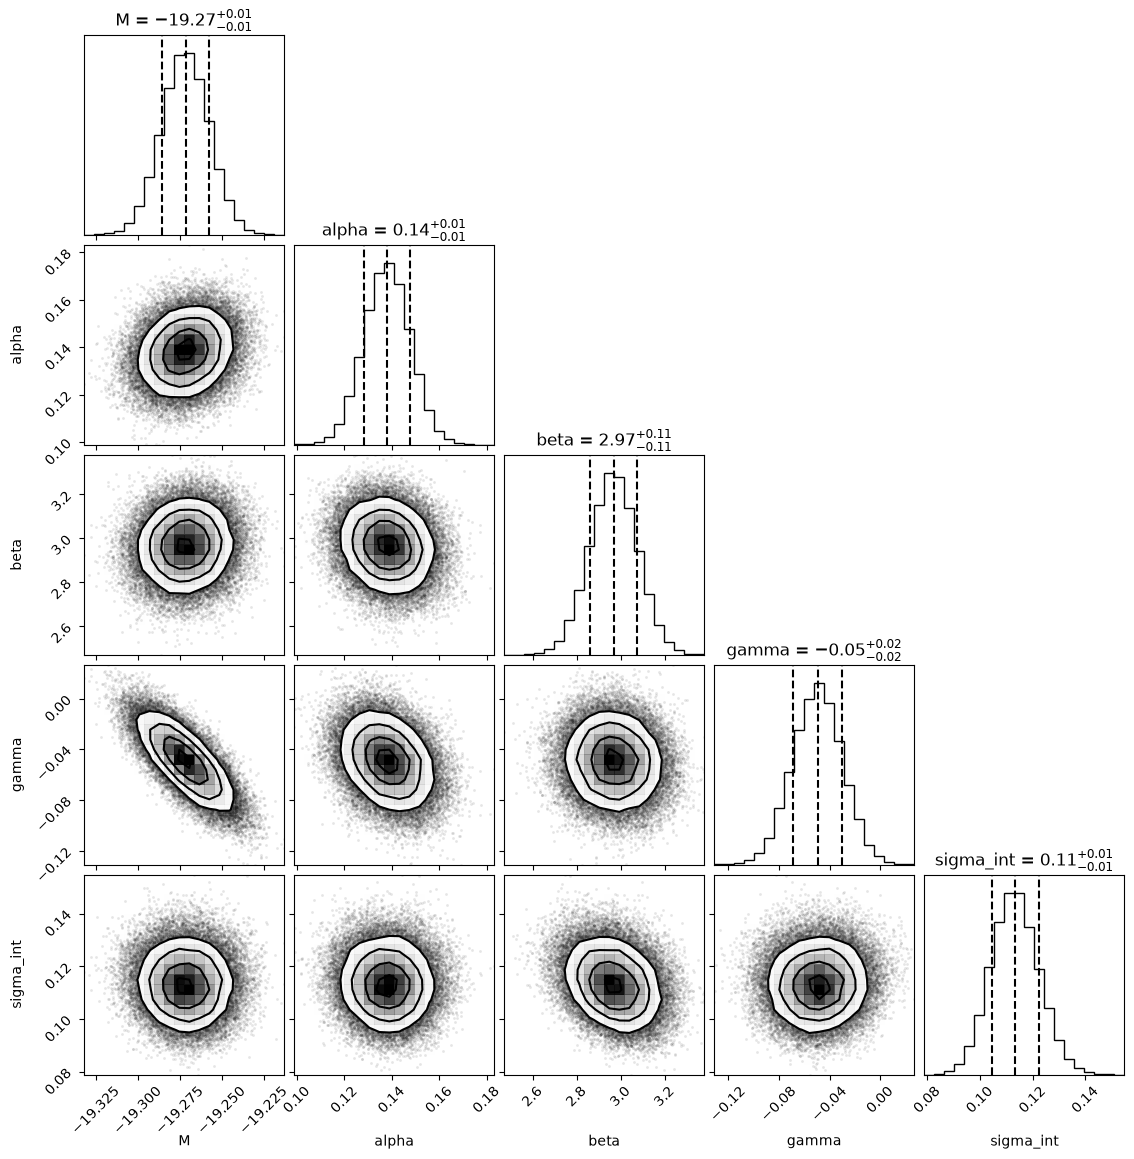

In [22]:
samples=chains.reshape(-1,ndim)
physical=samples.copy()
physical[:,4]=np.exp(physical[:,4])

corner.corner(
    physical,
    labels=['M','alpha','beta','gamma','sigma_int'],
    quantiles=[.16,.5,.84],
    show_titles=True
)
plt.show()

In [23]:
def report(x,name):
    q16,q50,q84=np.percentile(x,[16,50,84])
    print(f"{name} = {q50:.4f} +{q84-q50:.4f} -{q50-q16:.4f}")

report(samples[:,1],"alpha")
report(samples[:,2],"beta")
report(samples[:,3],"gamma")
report(np.exp(samples[:,4]),"sigma_int [mag]")
corr=np.corrcoef(physical.T)

print(pd.DataFrame(
    corr,
    index=['M','alpha','beta','gamma','sigma_int'],
    columns=['M','alpha','beta','gamma','sigma_int']
))
Mfix=map_par[0]

def log_post_fixed(x):
    alpha,beta,gamma,lns=x
    return log_posterior([Mfix,alpha,beta,gamma,lns])

rfix=minimize(
    lambda x:-log_post_fixed(x),
    map_par[[1,2,3,4]],
    method='Nelder-Mead'
)

center=rfix.x

rng=np.random.default_rng(501)
start=center+np.array([.005,.03,.005,.02])*rng.normal(size=(40,4))

sf=emcee.EnsembleSampler(40,4,log_post_fixed)
sf.run_mcmc(start,10000,progress=True)

tau_f=sf.get_autocorr_time()
fixed=sf.get_chain(
    discard=int(3*tau_f.max()),
    thin=max(1,int(tau_f.max()/2)),
    flat=True
)

gamma_marg=samples[:,3]
gamma_fixed=fixed[:,2]

print("Marginal sigma gamma =",np.std(gamma_marg))
print("Fixed-M sigma gamma =",np.std(gamma_fixed))
print("ratio =",np.std(gamma_fixed)/np.std(gamma_marg))

alpha = 0.1381 +0.0096 -0.0096
beta = 2.9687 +0.1078 -0.1081
gamma = -0.0493 +0.0194 -0.0196
sigma_int [mag] = 0.1132 +0.0092 -0.0088
                  M     alpha      beta     gamma  sigma_int
M          1.000000  0.187554  0.076744 -0.757835  -0.036754
alpha      0.187554  1.000000 -0.146540 -0.302584  -0.044343
beta       0.076744 -0.146540  1.000000 -0.081155  -0.268411
gamma     -0.757835 -0.302584 -0.081155  1.000000   0.037187
sigma_int -0.036754 -0.044343 -0.268411  0.037187   1.000000


100%|██████████| 10000/10000 [00:58<00:00, 171.62it/s]


Marginal sigma gamma = 0.01962169919095286
Fixed-M sigma gamma = 0.012871151599768399
ratio = 0.655965188055834


**ANSWER:**

*your answer goes here*

### 2d - Model comparison (10 pts)

Compare $M_0$ ($\gamma = 0$) with $M_1$ ($\gamma$ free).

1. Compute $2\ln B_{1,0}$ with the Laplace approximation (Day 13), with a prior on $\gamma$ you state and defend. How does it change if that prior is twice as wide?
2. Compute $\textrm{BIC}_0 - \textrm{BIC}_1$ for comparison.
3. How strong is your answer on Day 8's scale (0-2 weak, 2-6 positive, 6-10 strong, above 10 very strong)? Compare $\gamma$ with the published $-0.06$ mag. Could your 250 supernovae have detected a step that size? (One way: your $\sigma_\gamma$ tells you how many $\sigma$ a $-0.06$ step would be.)

In [24]:
# 2d: your work here
def loglike0(x):
    M,alpha,beta,lns=x
    return log_likelihood([M,alpha,beta,0.0,lns])

r0=minimize(
    lambda x:-loglike0(x),
    map_par[[0,1,2,4]],
    method='Nelder-Mead'
)

lnL0=loglike0(r0.x)
lnL1=log_likelihood(map_par)

print("lnL0 =",lnL0)
print("lnL1 =",lnL1)

N=len(mB)

BIC0=4*np.log(N)-2*lnL0
BIC1=5*np.log(N)-2*lnL1

delta_BIC=BIC0-BIC1

print("BIC0-BIC1 =",delta_BIC)
gamma_med=np.median(gamma_marg)
sigma_gamma=np.std(gamma_marg)

Wgamma=1.0

lnB10=np.log(
    Wgamma/(np.sqrt(2*np.pi)*sigma_gamma)
)-0.5*(gamma_med/sigma_gamma)**2
two_lnB=(gamma_med/sigma_gamma)**2 + 2*np.log(np.sqrt(2*np.pi)*sigma_gamma/Wgamma)

two_lnB_wide=(gamma_med/sigma_gamma)**2 + 2*np.log(np.sqrt(2*np.pi)*sigma_gamma/(2*Wgamma))

print("2 ln B10 =",two_lnB)
print("twice-wide prior =",two_lnB_wide)

lnL0 = 114.88506717182376
lnL1 = 118.03738389567494
BIC0-BIC1 = 0.80337523715761
2 ln B10 = 0.27743190307382193
twice-wide prior = -1.1088624580460689


**ANSWER:**

*your answer goes here*

### 2e - Testing your pipeline (8 pts)

Design one test of your pipeline that would come out differently if your pipeline were wrong, and run it. State **before** you run it what result would count as a failure. One suggestion: generate fake supernovae at your redshifts, stretches and colors from parameters you choose (including a $\gamma$ you choose), fit 30 or more such datasets (maximum-likelihood fits with curvature error bars are fine here; you don't need MCMC for each), and check how often your 68% intervals contain the truth.

In [25]:
# 2e: your work here
theta_true=map_par.copy()
theta_true[3]=-0.06

M_t,a_t,b_t,g_t,lns_t=theta_true
sint_t=np.exp(lns_t)

def variance(alpha,beta,sint):
    return (mb_err**2
            +alpha**2*x1_err**2
            +beta**2*c_err**2
            +2*alpha*cov_mx
            -2*beta*cov_mc
            -2*alpha*beta*cov_xc
            +sigma_pec**2+sint**2)

rng=np.random.default_rng(123)
nsim=50

gamma_hat=[]
gamma_err=[]
contains=[]

for j in range(nsim):

    model=M_t+mu-a_t*x1+b_t*c+g_t*step
    fake=model+rng.normal(0,np.sqrt(variance(a_t,b_t,sint_t)))

    def ll_fake(theta):
        M,alpha,beta,gamma,lns=theta
        sint=np.exp(lns)

        mod=M+mu-alpha*x1+beta*c+gamma*step
        var=variance(alpha,beta,sint)

        if np.any(var<=0):
            return -np.inf

        return -0.5*np.sum((fake-mod)**2/var+np.log(2*np.pi*var))

    r=minimize(lambda x:-ll_fake(x),theta_true,method='BFGS')

    gamma_hat.append(r.x[3])

    if r.hess_inv is not None:
        sg=np.sqrt(r.hess_inv[3,3])
        gamma_err.append(sg)
        contains.append(abs(r.x[3]-g_t)<=sg)

gamma_hat=np.array(gamma_hat)
gamma_err=np.array(gamma_err)
contains=np.array(contains)

print("mean recovered gamma =",gamma_hat.mean())
print("true gamma =",g_t)
print("bias =",gamma_hat.mean()-g_t)
print("68% coverage =",contains.mean())

mean recovered gamma = -0.056936438944176763
true gamma = -0.06
bias = 0.0030635610558232343
68% coverage = 0.7


**ANSWER:**

*your answer goes here*

## Part 3: The referee report (25 pts)

White dwarfs are the cores of dead stars like the Sun. Your file `p3_wd_masses.csv` holds 600 real DA (hydrogen-atmosphere) white dwarfs from the 100 pc sample of [Kilic et al. (2020)](https://arxiv.org/abs/2006.00323), ApJ 898, 84: `name`, `teff_K`, `mass_Msun`, `mass_err_Msun`. Most single white dwarfs have masses near $0.6\,M_\odot$; Kilic et al. report a narrow peak there plus an excess of more massive ones, around $0.7$-$0.9\,M_\odot$, which merger products alone do not explain.

The notebook `labs/midterm/ai_solution.ipynb` fits your masses with a two-population model using `emcee`. Run it from that directory, after setting `NETID` in its first cell. It runs top to bottom and the plots look nice, but it's wrong in at least three substantive ways - and if you don't look at your data, you'll fool yourself the same way.

### 3a - The report (20 pts)

1. **Identify** at least three substantive errors (not style; "it used 32 walkers and I'd use 48" is not one).
2. **Demonstrate** each on *your* file: show, with a number or a plot, what the error does to the answer. A demonstration can come out negative: if an error doesn't move your numbers, show that, and say what it would take for it to matter.
3. **State** the correct treatment, and run it where you can.

1.It 3σ clips the white-dwarf masses before fitting, potentially deleting the scientifically interesting high-mass population.
2. It ignores each star's mass_err_Msun, even though these measurement errors belong in the mixture likelihood.

Total = 600
Removed = 12
Removed masses = [1.182 1.276 1.213 1.143 1.282 1.215 1.278 1.144 1.171 1.129 1.263 1.321]


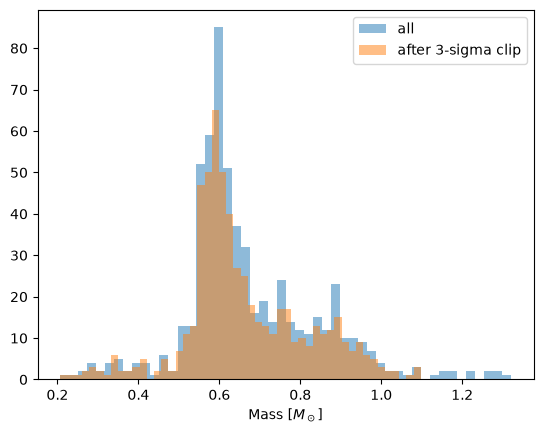

In [26]:
# 3a: your work here
p3=load('p3_wd_masses')

mass=p3['mass_Msun'].to_numpy()
masserr=p3['mass_err_Msun'].to_numpy()

med=np.median(mass)
sd=np.std(mass)

keep=np.abs(mass-med)<3*sd

print("Total =",len(mass))
print("Removed =",np.sum(~keep))
print("Removed masses =",mass[~keep])

plt.hist(mass,bins=50,alpha=.5,label='all')
plt.hist(mass[keep],bins=50,alpha=.5,label='after 3-sigma clip')
plt.xlabel(r'Mass [$M_\odot$]')
plt.legend()
plt.show()

In [27]:
def log_prob_correct(p,m,sm):
    mu1,s1,mu2,s2,f=p

    if not (0.3<mu1<mu2<1.3 and
            0.005<s1<0.5 and
            0.005<s2<0.5 and
            0<f<1):
        return -np.inf

    sig1=np.sqrt(s1**2+sm**2)
    sig2=np.sqrt(s2**2+sm**2)

    p1=f*stats.norm.pdf(m,mu1,sig1)
    p2=(1-f)*stats.norm.pdf(m,mu2,sig2)

    return np.sum(np.log(p1+p2))

def log_prob_ai(p,m):
    mu1,s1,mu2,s2,f=p

    if not (0.3<mu1<1.3 and
            0.3<mu2<1.3 and
            0.005<s1<0.5 and
            0.005<s2<0.5 and
            0<f<1):
        return -np.inf

    return np.sum(np.log(
        f*stats.norm.pdf(m,mu1,s1)
        +(1-f)*stats.norm.pdf(m,mu2,s2)
    ))

lo=mass[mass<0.7]
hi=mass[mass>=0.7]

p0=np.array([
    lo.mean(),lo.std(),
    hi.mean(),hi.std(),
    len(lo)/len(mass)
])

fit_ai=minimize(lambda p:-log_prob_ai(p,mass),p0,method='Nelder-Mead')
fit_good=minimize(lambda p:-log_prob_correct(p,mass,masserr),p0,method='Nelder-Mead')

names=['mu1','sigma1','mu2','sigma2','f']

for name,a,b in zip(names,fit_ai.x,fit_good.x):
    print(f"{name:7s} AI={a:.4f} correct={b:.4f} difference={b-a:+.4f}")

mu1     AI=0.5937 correct=0.5941 difference=+0.0004
sigma1  AI=0.0335 correct=0.0304 difference=-0.0030
mu2     AI=0.7255 correct=0.7271 difference=+0.0016
sigma2  AI=0.1979 correct=0.1992 difference=+0.0012
f       AI=0.4011 correct=0.4132 difference=+0.0121


**REFEREE REPORT:**



### 3b - AI-use appendix (5 pts)

1. Which tools did you use, for what, what did they get wrong, and how did you catch it? "I used ChatGPT to help" is useless; "none" is fine if that's true. I promise I don't care which - just be honest about what you did.
2. What would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing, in two or three sentences.

**AI-USE APPENDIX:**
I used ChatGPT to help me write and debug Python code, and interpret the outputs.it suggested starting walkers in a tight ball around one solution,and some early code did not fully respect the convergence checks. I caught these by comparing the suggestions with the lecture notes, running the code, checking emcee autocorrelation errors

I could have reported posterior uncertainties from chains that had not actually converged.

Get started. You know how to do all of this. If not, there's something in a lab or class notebook that can help. Slack me with questions. Best of luck.